In [1]:
import numpy as np
#import lightkurve as lk
from astroquery.mast import Observations
import matplotlib.pyplot as plt
from astropy import units as u

from astropy.timeseries import LombScargle

from astropy.io import fits

%matplotlib inline

## Get obs from MAST


Currently:
* takes in TIC ID / sector
* downloads matching TESS-SPOC LC
* returns local path to file

Improvements:
* "functionalize" the code
* this could be run without downloads on TIKE (limited application when there are so few targets?)

In [2]:
def get_fits_path(tid, sector):
    ''' Given a TIC ID and sector,
    download the LC file and return the local path
    '''
    obs = Observations.query_criteria(target_name=tid
                                      , provenance_name='SPOC'
                                      , sequence_number=sector)
    prod = Observations.get_product_list(obs)
    lc = Observations.download_products(prod[0])

    fits_path = lc['Local Path'][0]
    return fits_path

fits_path = get_fits_path(442871031, 32)

INFO: Found cached file ./mastDownload/TESS/tess2020324010417-s0032-0000000442871031-0200-s/tess2020324010417-s0032-0000000442871031-0200-s_lc.fits with expected size 1903680. [astroquery.query]


## Parse Quality Flags

Given a fits path, read in the data and then keep only the data suitable for anaylsis.

In [3]:
def parse_quality(fits_path):
    ''' Read in a fits path, output the times / fluxes
    (remove the "bad quality" values from both)
    Also remove NaNs, or else we can't generate periodograms
    '''
    # Open file, read in the times, SAP flux, and quality flags
    with fits.open(fits_path, mode="readonly") as hdulist:
        tmz = hdulist[1].data['TIME']
        pdc_fluxes = hdulist[1].data['PDCSAP_FLUX']
        quality = hdulist[1].data['QUALITY']
        pdc_error = hdulist[1].data['PDCSAP_FLUX_ERR']
    
    # Convert flags to binary
    bad_bits = np.array([1,2,3,4,5,6,8,10,12,13,15])
    value = 0
    for v in bad_bits:
        value = value + 2**(v-1)
    
    # "bad data" will match the quality flags
    bad_quality = np.bitwise_and(quality, value) >= 1
    
    # Include any NaNs in bad data, 
    nan_data = np.isnan(pdc_fluxes)
    
    # Concat bad quality and NaN indexes
    bad_data = np.logical_or(bad_quality, nan_data)
    
    return tmz[~bad_data], pdc_fluxes[~bad_data], pdc_error[~bad_data]

In [4]:
tmz, fluxz, er = parse_quality(fits_path)

## Generate Preview / Periodogram Plots

Take in the cleaned data from above, generate a periodogram. Then make some plots

To do:
* LombScargle input frequencies need to be determined, rather than set. 
  * Upper limit on frequencies comes from TESS sampling rate (nyquist)
  * Lower limit on freq comes from length of data, we need at least two full periods to find a peak
  * Frequency spacing should go as $N_{eval}=n_oTf_{max}$ in order to sufficiently sample all peaks
    * $f_{max}$ is determined above
    * $T$ is the length of the data
    * $n_o$ is how many times we want to sample each peak; 5 is likely sufficient
* Add period axis to the top
  * Generalize the x-tick setting function

[0.00277786 0.00277786 0.00138893 ... 0.00138887 0.00138887 0.00138887] d


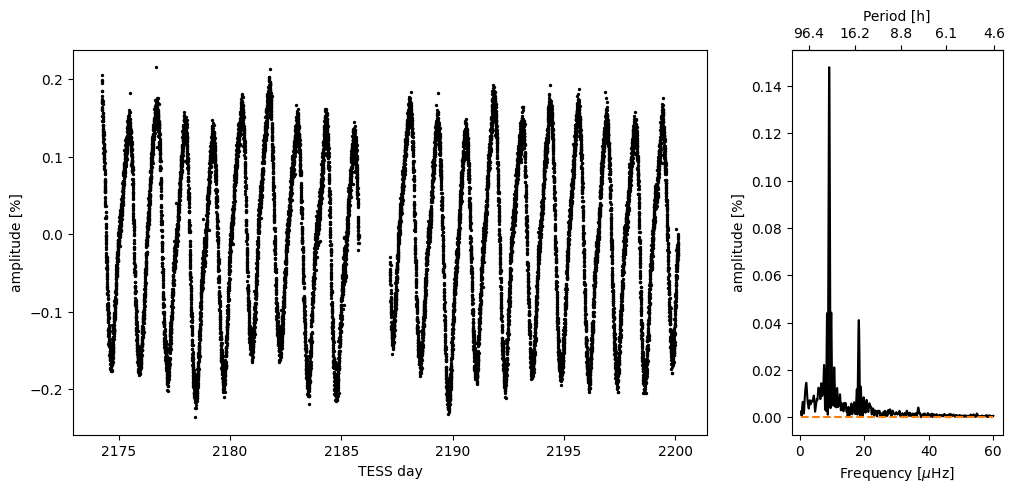

In [10]:
def make_pgrm(t, f, f_err):
    f_norm = f/np.median(f)
    f_err = f_err/np.median(f)
    
    # get right units for LS, make input freqs
    t = t*u.day
    print(t[1:]-t[:-1])
    freqs = np.linspace(0.5, 60, 50000) * u.microhertz
    
    # do psd lombscargle
    LS = LombScargle(t, f_norm, normalization='psd')
    pwrs = LS.power(freqs)
    max_p = max(pwrs)
    
    # get false alarm probability for maximum peak
    LS_err = LombScargle(t, f_norm, f_err, normalization='psd')
    max_pwr_err = LS_err.power(freqs).max()
    sigma3 = float(LS_err.false_alarm_level(0.997))*max_p/max_pwr_err
    
    # special correction to convert to amplitude
    pwrs = np.sqrt(pwrs) * np.sqrt(4.0 / len(t))
    sigma3 = np.sqrt(sigma3) * np.sqrt(4.0 / len(t))
    return freqs, pwrs, sigma3
    

def make_plots(t, f, freqs, pwrs, sigma3):
    f_norm = f/np.nanmedian(f)
    fig, (ax1,ax2) = plt.subplots(1,2, figsize=(12,5), gridspec_kw={'width_ratios':[3,1]})
    # plot lc
    ax1.scatter(t ,(f_norm-1)*100 ,c='black',s=2)
    ax1.set_xlabel('TESS day')
    ax1.set_ylabel('amplitude [%]')
    
    # plot prgm
    ax2.plot(freqs, pwrs*100, c='black')
    ax2.set_xlabel('Frequency [$\mu$Hz]')
    ax2.set_ylabel('amplitude [%]')
    ax2.hlines(sigma3*100, freqs[0].value, freqs[-1].value, linestyles='dashed', colors='tab:orange')
    
    # Set up period at top
    def invert(x):
        # 1/x with special treatment of x == 0
        x = np.array(x).astype(float)
        near_zero = np.isclose(x, 0)
        x[near_zero] = np.inf
        x[~near_zero] = 277.77778 / x[~near_zero]
        return np.around(x, decimals=1)
    per_ax2 = ax2.secondary_xaxis('top', functions=(invert, invert))
    per_ax2.set_xticks(invert(freqs)[2000::11999])
    per_ax2.set_xlabel('Period [h]')
    
freqs, pwrs, sigma3 = make_pgrm(tmz,fluxz, er)
make_plots(tmz, fluxz, freqs, pwrs, sigma3)

In [11]:
fluxz

array([2627158.5, 2627177.2, 2627096.8, ..., 2621614.8, 2621651. ,
       2621883.8], dtype='>f4')

In [12]:
er

array([173.32176, 173.29233, 173.29498, ..., 173.75475, 173.76076,
       173.78535], dtype='>f4')

In [13]:
sigma3

<Quantity 3.16987446e-06>

## Calculate Vital Statistics

For stars with variability, get:
* period
* max amp
* $V_{95}$

In [198]:
def vital_stats(flux, freqs, pwrs):
    f_norm = flux/np.median(flux)
    # Convert the period to days
    prd = (1/pwrs.max).to(u.day)
    a_max = pwrs.max()*100
    V95 = 100*(np.nanpercentile(f_norm,97.725) - np.nanpercentile(f_norm,2.275))
    return prd, a_max, V95

for v in vital_stats(sap_fluxz, freqs, pwrs):
    print(v)

TypeError: unsupported operand type(s) for /: 'int' and 'builtin_function_or_method'

In [199]:
type(pwrs)

astropy.units.quantity.Quantity

### Expected vs. actual

| | Susan | Thomas|
|--|------|-------|
|Period (d)| 1.260 | 1.261|
|Max amp(%) | 0.148 | 0.147|
|V95 (%)| 0.35 | 0.37|

Period within error stated in paper, although odd that it does not match exactly.

Slight variations in amplitude figures (probably) due to my lack of 6-minute bins.

## TO DO:
* Add 6 minute bins

# TO DO:

For stars with no significant variations:
* calculate $A^{max}_{1d}$
    * Q4S: define significant variation. Max amp < [???]
    * TD guess: less than error for a star of that magnitude
* calculate $V_{99.7}$

INFO: Found cached file ./mastDownload/TESS/tess2019331140908-s0019-0000000327587572-0164-s/tess2019331140908-s0019-0000000327587572-0164-s_lc.fits with expected size 1834560. [astroquery.query]


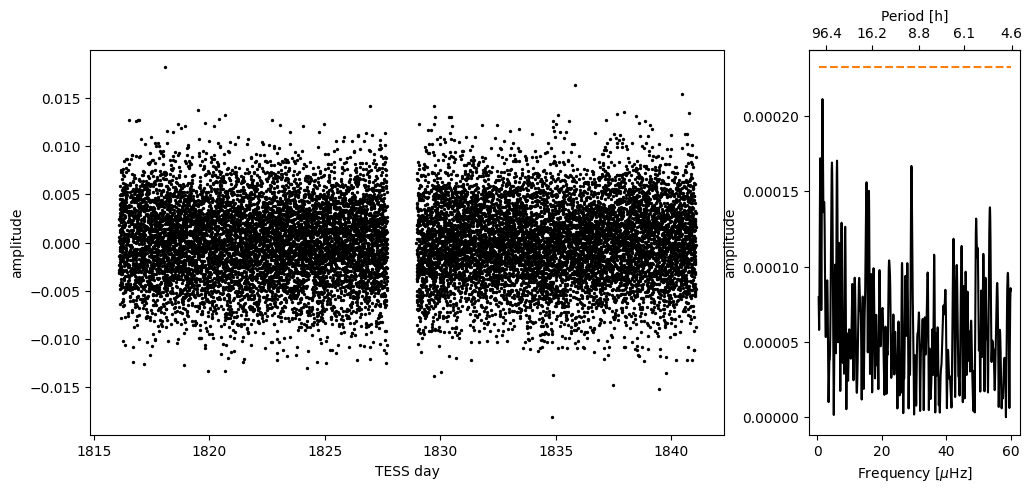

In [274]:
b2b = 327587572
s = 19

fp = get_fits_path(b2b, s)
t, f, err = parse_quality(fp)
freq, pwrs, p_fa, s3 = make_pgrm(t, f, err)
make_plots(t, f, freq, pwrs, s3)

In [278]:
s3

<Quantity 0.00023248>

In [93]:
from scipy.signal import savgol_filter as sf

In [100]:
dt = t[1:]-t[0:-1]

In [181]:
cut = np.where(dt > 5*np.nanmedian(dt))
low = np.append([0], cut)
high = np.append(cut, len(t))

In [188]:
trend = np.zeros(len(t))
for l,h in zip(low,high):
    wl = (h-l)//2
    trend[l:h] = sf(f[l:h], wl, 2)

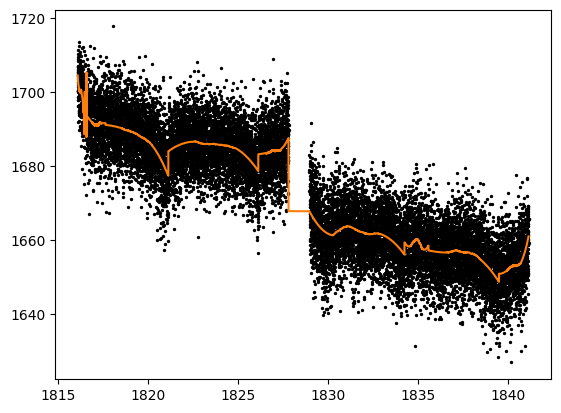

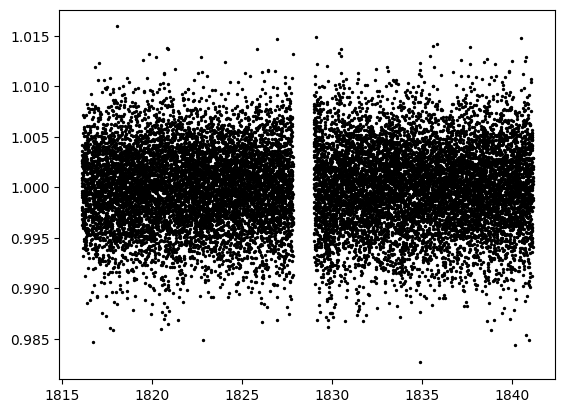

In [189]:
#fctr = 0.2
#trend = sf(f, int(fctr*len(dt)), 2)

plt.scatter(t,f,s=2,c='k')
plt.plot(t, trend, c='tab:orange')

plt.figure()
plt.scatter(t, (f/trend), s=2,c='k')

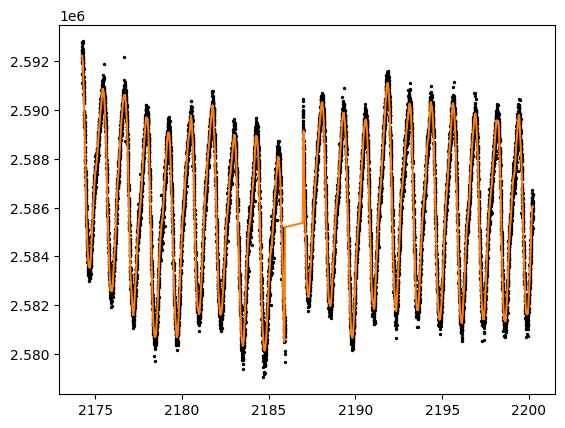

In [118]:
plt.scatter(tmz, sap_fluxz, s=2, c='k')
plt.plot(tmz, sf(sap_fluxz, 101, 2), c='tab:orange')

In [16]:
freq, pwrs = make_pgrm(t,f)

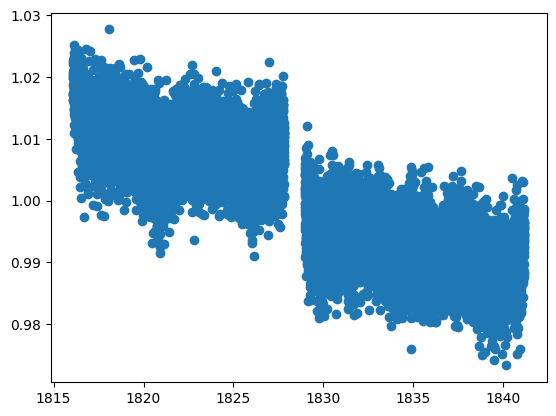

In [30]:
plt.scatter(t,f/np.nanmedian(f))

In [40]:
for a in f:
    if not a > 0:
        print(type(a))

<class 'numpy.float32'>
<class 'numpy.float32'>


In [54]:
np.argwhere(np.isnan(f)).flatten()

array([15225, 15226])

In [79]:
np.bitwise_or(np.isnan(f), np.isnan(f))

array([False, False, False, ...,  True,  True,  True])

In [47]:
f[np.isnan(f)]

array([nan, nan], dtype='>f4')

In [48]:
idx = np.array([0])

In [55]:
np.concatenate((idx, np.argwhere(np.isnan(f)).flatten()))

array([    0, 15225, 15226])